# Phase 9 — Audit d'équité

**Question :** le modèle est-il aussi fiable pour tous les groupes de clients, et ses décisions diffèrent-elles entre groupes pour de bonnes raisons ?

**Ce que signifie « être ciblé » ici.** Être contacté = **recevoir une offre** (remise, service offert). C'est un **avantage** pour le client. Le risque d'injustice n'est donc pas d'être ciblé à tort, mais d'être **oublié** : un groupe dont le risque serait sous-estimé serait privé d'offres.

**Critère principal : la calibration par groupe.** Un risque annoncé de 30 % doit correspondre à 30 % de départs **dans chaque groupe**. Si c'est le cas, les décisions reposent sur un risque juste pour tout le monde, et les écarts de taux de contact reflètent des écarts **réels** de risque et de valeur.

**Groupes examinés** (jeu de test, 1 409 clients) : genre (retiré du modèle en Phase 4), senior, personnes à charge.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from churn.business import expected_gain
from churn.config import DROPPED_COLS
from churn.data import load_clean
from churn.fairness import group_report
from churn.features import build_pipeline, split_data
from churn.models import evaluate_cv, load_model, make_cv, corrected_paired_ttest
from churn.viz import set_style, save_fig, fmt_pct, BLUE, ORANGE, AQUA, TEXT, TEXT_SECONDARY, GRID

warnings.filterwarnings("ignore", category=UserWarning)
set_style()
dec = lambda v, d=3: f"{v:.{d}f}".replace(".", ",")

X_train, X_test, y_train, y_test = split_data(load_clean())
model, card = load_model("churn_model")
proba = model.predict_proba(X_test)[:, 1]
contacted = expected_gain(proba, X_test["MonthlyCharges"]) > 0   # règle de décision de la Phase 6

GROUPS = {"gender": ("Genre", {"Male": "Homme", "Female": "Femme"}),
          "SeniorCitizen": ("Senior", {"No": "Non senior", "Yes": "Senior"}),
          "Dependents": ("Personnes à charge", {"No": "Sans", "Yes": "Avec"})}
reports = {}
for col, (title, names) in GROUPS.items():
    r = group_report(y_test, proba, contacted, X_test[col]).rename(index=names)
    reports[title] = r
report = pd.concat(reports, names=["variable", "groupe"])
report.style.format({"churn_rate": "{:.1%}", "mean_pred": "{:.1%}", "calibration_gap": "{:+.1%}",
                     "gap_ci_low": "{:+.1%}", "gap_ci_high": "{:+.1%}", "pr_auc": "{:.3f}", "roc_auc": "{:.3f}",
                     "contact_rate": "{:.0%}", "recall": "{:.0%}", "false_positive_rate": "{:.0%}"})

## 1. Le risque est-il aussi juste pour chaque groupe ?

Pour chaque groupe : risque moyen **prédit** (point bleu) contre taux de départ **observé** (losange orange), avec l'intervalle de confiance à 95 % (bootstrap) de l'écart.

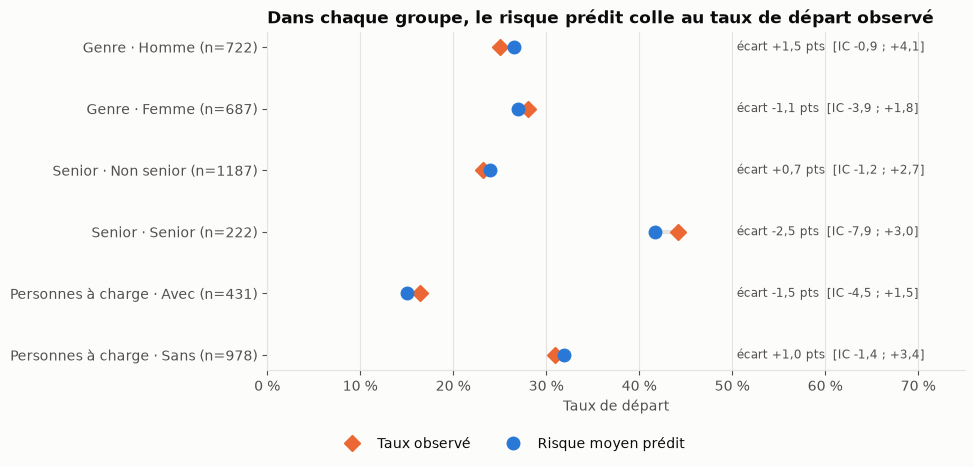

In [2]:
rows = report.reset_index()
fig, ax = plt.subplots(figsize=(9, 4.4))
for i, r in rows.iloc[::-1].reset_index(drop=True).iterrows():
    ax.plot([r["churn_rate"], r["mean_pred"]], [i, i], color=GRID, lw=3, zorder=1)
    ax.plot(r["churn_rate"], i, "D", color=ORANGE, markersize=8, zorder=2, label="Taux observé" if i == 0 else None)
    ax.plot(r["mean_pred"], i, "o", color=BLUE, markersize=9, zorder=3, label="Risque moyen prédit" if i == 0 else None)
    gap_txt = f"écart {r['calibration_gap'] * 100:+.1f} pts  [IC {r['gap_ci_low'] * 100:+.1f} ; {r['gap_ci_high'] * 100:+.1f}]"
    ax.text(0.505, i, gap_txt.replace(".", ","), va="center", fontsize=8.5, color=TEXT_SECONDARY)
ax.set_yticks(range(len(rows)), [f"{v} · {g} (n={n})" for v, g, n in rows.iloc[::-1][["variable", "groupe", "n"]].values])
ax.set_xlim(0, 0.75)
ax.xaxis.set_major_formatter(lambda v, _: fmt_pct(v, 0))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Taux de départ")
ax.legend(loc="upper center", bbox_to_anchor=(0.35, -0.16), ncol=2)
ax.set_title("Dans chaque groupe, le risque prédit colle au taux de départ observé")
save_fig(fig, "08_equite_calibration.png")
plt.show()

**Lecture :** pour les six groupes, le risque moyen prédit est à moins de 3 points du taux observé, et **tous les intervalles de confiance contiennent 0** : aucune sous-estimation ni surestimation significative. Aucun groupe n'est systématiquement « oublié » par le modèle.

- **Genre** : le modèle n'utilise pas le genre (retiré en Phase 4), et ses performances sont identiques pour les femmes et les hommes (ROC-AUC 0,843 contre 0,854). Aucune autre variable ne joue le rôle de « proxy » du genre.
- **Seniors** : la calibration tient (écart −2,5 points, non significatif), mais l'échantillon est petit (222 clients) et l'intervalle large. Point d'attention : la **ROC-AUC est plus faible** chez les seniors (0,784 contre 0,849) : le modèle distingue moins bien, **entre eux**, les seniors qui partent de ceux qui restent.

## 2. Les décisions diffèrent-elles entre groupes, et pourquoi ?

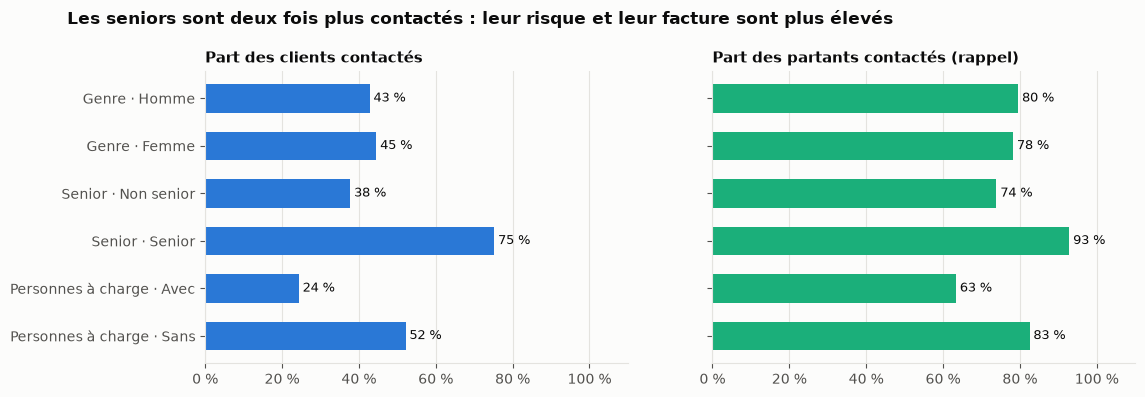

,taux de départ observé,facture moyenne ($)
Non senior,23.3%,61.3
Senior,44.1%,79.2


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
labels = [f"{v} · {g}" for v, g in rows[["variable", "groupe"]].values][::-1]
for ax, col, title, color in [(axes[0], "contact_rate", "Part des clients contactés", BLUE),
                              (axes[1], "recall", "Part des partants contactés (rappel)", AQUA)]:
    vals = rows[col].to_numpy()[::-1]
    ax.barh(labels, vals, color=color, height=0.6)
    for i, v in enumerate(vals):
        ax.text(v + 0.01, i, fmt_pct(v, 0), va="center", fontsize=9, color=TEXT)
    ax.set_xlim(0, 1.1)
    ax.xaxis.set_major_formatter(lambda v, _: fmt_pct(v, 0))
    ax.grid(axis="y", visible=False)
    ax.set_title(title, fontsize=11)
fig.suptitle("Les seniors sont deux fois plus contactés : leur risque et leur facture sont plus élevés",
             x=0.01, ha="left", fontsize=12, fontweight="bold", color=TEXT, y=1.04)
save_fig(fig, "08_equite_decisions.png")
plt.show()

why = pd.DataFrame({"taux de départ observé": X_test.assign(y=y_test.to_numpy()).groupby("SeniorCitizen", observed=True)["y"].mean(),
                    "facture moyenne ($)": X_test.groupby("SeniorCitizen", observed=True)["MonthlyCharges"].mean()})
why.index = ["Non senior", "Senior"]
why.style.format({"taux de départ observé": "{:.1%}", "facture moyenne ($)": "{:.1f}"})

**Lecture :**
- **Seniors contactés deux fois plus** (75 % contre 38 %). Ce n'est pas un biais du modèle : les seniors partent **réellement** deux fois plus (44 % contre 23 %) et paient **plus cher** (79 $ contre 61 $), deux raisons qui rendent l'appel rentable. Rappel de la Phase 7 : à autres variables fixées, être senior ne pèse presque rien (×1,2) ; ce sont leur contrat, leur fibre et leur facture qui portent le risque.
- **Clients avec personnes à charge** : moins contactés (24 %), et leurs partants sont moins souvent atteints (rappel 63 % contre 82 %). Leur risque est réellement plus faible (16,5 % de départs) et leur facture plus basse : la règle les juge moins souvent rentables. C'est **cohérent avec l'objectif de gain**, mais c'est un choix à assumer : si l'entreprise veut fidéliser les familles pour d'autres raisons, il faut une règle dédiée.
- **Genre** : taux de contact et rappel quasi identiques.

## 3. Peut-on retirer l'âge du modèle ?

L'âge est un attribut protégé dans de nombreuses réglementations (ex. non-discrimination en Europe). Le modèle utilise `SeniorCitizen`. Si on le retire, perd-on en performance ? Même protocole qu'en Phase 5 (15 plis, t-test corrigé).

In [4]:
cv = make_cv()
params = {k: v for k, v in card["hyperparameters"].items()}
from sklearn.linear_model import LogisticRegression
base_model = LogisticRegression(**params)
with_age = evaluate_cv(build_pipeline(base_model), X_train, y_train, cv=cv)
without_age = evaluate_cv(build_pipeline(LogisticRegression(**params), drop_cols=tuple(DROPPED_COLS) + ("SeniorCitizen",)),
                          X_train, y_train, cv=cv)
test = corrected_paired_ttest(with_age["pr_auc_folds"], without_age["pr_auc_folds"])
pd.DataFrame({"avec SeniorCitizen": {k: with_age[k] for k in ("pr_auc", "roc_auc", "brier")},
              "sans SeniorCitizen": {k: without_age[k] for k in ("pr_auc", "roc_auc", "brier")}}).style.format("{:.4f}")

,avec SeniorCitizen,sans SeniorCitizen
pr_auc,0.6746,0.6749
roc_auc,0.8511,0.8511
brier,0.1326,0.1327


In [5]:
print(f"Écart de PR-AUC (avec − sans) : {test['mean_diff']:+.4f}, p-value = {dec(test['p_value'])}")

Écart de PR-AUC (avec − sans) : -0.0003, p-value = 0,779


**Lecture :** retirer `SeniorCitizen` ne change **rien** à la performance (écart de PR-AUC de l'ordre du dix-millième, p = 0,78). L'information qu'il portait est déjà dans le contrat, le type d'internet et la facture.

**Recommandation pour la version 2 du modèle : retirer `SeniorCitizen`.** On supprime l'usage d'un attribut protégé sans aucune perte. Le modèle actuel n'est pas réentraîné ici : les chiffres validés des phases 6 à 8 et l'application déployée reposent sur lui. Ce changement suivrait un cycle de mise à jour complet (réentraînement, réévaluation, redéploiement).

## Conclusion de l'audit

| Question | Réponse |
|---|---|
| Le risque est-il juste pour chaque groupe ? | **Oui.** Aucun écart de calibration significatif (tous les IC 95 % contiennent 0), pour le genre, l'âge et les personnes à charge. |
| Les performances sont-elles homogènes ? | Oui pour le genre. **Point d'attention :** classement moins fin chez les seniors (ROC-AUC 0,78 contre 0,85), sur un petit effectif. |
| Les décisions diffèrent-elles ? | Oui : seniors deux fois plus contactés, familles moins. Ces écarts suivent des différences **réelles** de risque et de valeur client, pas un biais du modèle. |
| Le modèle utilise-t-il des attributs protégés ? | Le genre : non. L'âge (senior) : oui, mais il est **inutile** → à retirer en version 2. |

**Limites de l'audit :** effectifs modestes (222 seniors), une seule date d'observation, pas d'autres attributs sensibles disponibles dans les données. **En production**, ces indicateurs doivent être **suivis dans le temps** (calibration et taux de contact par groupe, à chaque campagne).